In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.stats import norm


In [ ]:
class F_sine:
    def __init__(self, npts, A):
        self.npts = npts
        self.x_min = 0
        self.x_max = 2*np.pi
        self.x = np.linspace(self.x_min, self.x_max, self.npts, endpoint=False)
        self.F = A*np.sin(self.x)  # Example function; replace with actual function as needed

    def evaluate(self):
        return self.x, self.F

    def plot(self):
        x, F = self.evaluate()
        plt.plot(x, F)
        plt.title("sin(x)")
        plt.xlabel("x (radians)")
        plt.ylabel("F (energy)")
        plt.xlim(self.x_min, self.x_max)
        plt.show()

s1 = F_sine(npts=100, A=1)
s1.plot()

In [ ]:
class F_2sine:
    def __init__(self, npts, A):
        self.npts = npts
        self.x_min = 0
        self.x_max = 2*np.pi
        self.x = np.linspace(self.x_min, self.x_max, self.npts, endpoint=False)
        self.F = A*np.sin(2*self.x)  # Example function; replace with actual function as needed

    def evaluate(self):
        return self.x, self.F

    def plot(self):
        x, F = self.evaluate()
        plt.plot(x, F)
        plt.title("sin(2x)")
        plt.xlabel("x (radians)")
        plt.ylabel("F (energy)")
        plt.xlim(self.x_min, self.x_max)
        plt.show()

s2 = F_2sine(npts=100, A=5)
s2.plot()

In [ ]:
npts = 1000
A=5
s1 = F_2sine(npts, A)
#s1.plot()
x, F = s1.evaluate()

nrounds = 10000
sigma = 0.1
omega = 1
deltaT = 10
kB=1
T=1

ref_gaussian = norm.pdf(x, loc=0, scale=sigma)
# Normalization condition given that the gaussian includes only the positive numbers
#A*(2*np.sum(ref_gaussian)-ref_gaussian[0]) = 1  
ref_gaussian /= (2*np.sum(ref_gaussian)-ref_gaussian[0])  # Normalize the reference Gaussian

# plt.plot(x, ref_gaussian)
# plt.show()
# print(np.sum(ref_gaussian))  # Should be ~1/2
# print(ref_gaussian[0])

bin_inds = np.arange(npts)

bin_trj = np.zeros(nrounds, dtype=int)
V = np.zeros((nrounds+1, npts))

rounds = np.arange(nrounds)

for t in rounds:

    #calculate probability density
    prob_unnorm = np.exp(-(F+V[t])/(kB*T))
    probability_density = prob_unnorm/np.sum(prob_unnorm)

    #select a bin
    bin = np.random.choice(bin_inds, p=probability_density) #probabilities must sum to 1
    bin_trj[t] = bin

    #calculate minimum image index distances of all other bins from the selected bin
    minimum_image_index_distances_lower = np.abs(bin-bin_inds)
    minimum_image_index_distances_upper = npts-np.abs(bin-bin_inds)
    minimum_image_index_distances = np.min(np.array([minimum_image_index_distances_lower, minimum_image_index_distances_upper]), axis=0)

    # plt.plot(ref_gaussian[minimum_image_index_distances])
    # print(np.sum(ref_gaussian[minimum_image_index_distances]))
    #deposit potential
    V[t+1] = V[t] + omega*np.exp(-V[t,bin]/(kB*deltaT))*ref_gaussian[minimum_image_index_distances]

    # print("bin:", bin)
    #print(minimum_image_index_distances)
    #break

    if t % int(nrounds/10) == 0:
        plt.plot(x, V[t])
        #plt.title("V(t) at t = {}".format(t))
        plt.xlabel("x (radians)")
        plt.ylabel("V (bias potential)")
        plt.xlim(0, 2*np.pi)
        #plt.show()
                                           
    #np.array([min(abs(bin-i), npts-abs(bin-i)) for i in range(npts)])


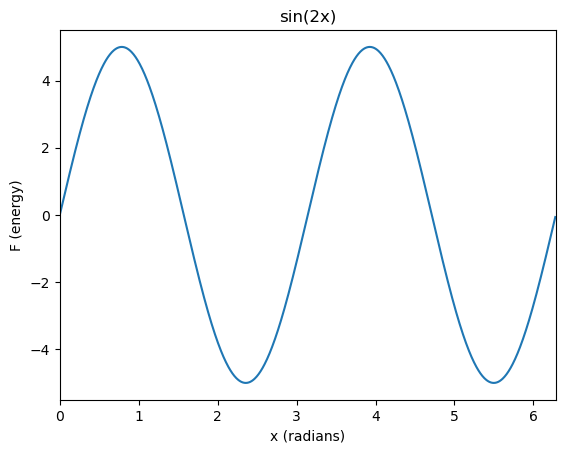

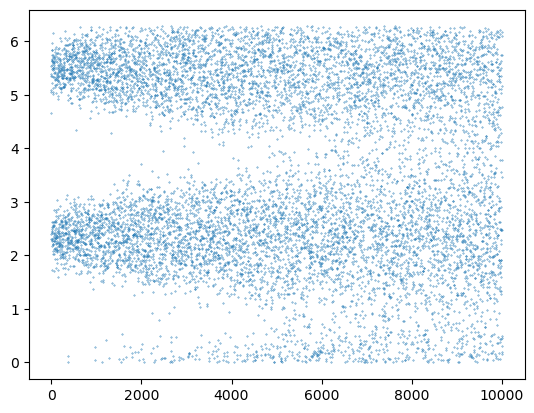

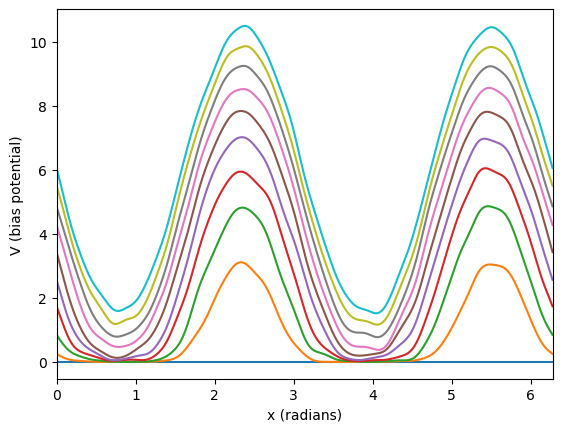

In [4]:
import mc_discrete_1d_metadynamics as mc
import cyclic_systems as cs
import matplotlib.pyplot as plt
import numpy as np
import importlib
importlib.reload(mc)
importlib.reload(cs)


nrounds = 10000
sigma = 0.1
omega = 1
deltaT = 10
kB=1
T=1

npts = 1000
A=5
s1 = cs.F_2sine(npts, A)
s1.plot()
x, F = s1.evaluate()

rounds, bin_trj, V = mc.monte_carlo_discrete_1d_metadynamics(s1, sigma, omega, deltaT, kB, T, nrounds)

plt.scatter(rounds, x[bin_trj], s=0.1)
plt.show()

for t in rounds[::int(nrounds/10)]:
    plt.plot(x, V[t])
    plt.xlabel("x (radians)")
    plt.ylabel("V (bias potential)")
    plt.xlim(0, 2*np.pi)
